In [75]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kstest

In [76]:
files = ["../mu-8.1/insertion_quaternions.csv",
         "../mu-8.1_modified/insertion_quaternions.csv"]
output_files = ["insertion_orientation_distribution_legacy.png",
                "insertion_orientation_distribution_modified.png"]
mode = 0  # Change to 1 for the modified file
data = np.atleast_1d(
    np.genfromtxt(files[mode],
                  delimiter=",", names=True)
)

q = np.column_stack([
    data["qw"], data["qx"], data["qy"], data["qz"]
])

if not np.isfinite(q).all():
    raise ValueError("Quaternion file contains non-finite values.")

In [77]:
norms = np.linalg.norm(q, axis=1)
if np.any(norms == 0):
    raise ValueError("Found a zero quaternion.")

print(f"Number of attempts: {len(q)}")
print(f"Maximum norm error: {np.max(np.abs(norms - 1)):.3e}")

Number of attempts: 249585
Maximum norm error: 3.331e-16


In [78]:
# Remove floating-point norm errors.
q = q / norms[:, None]
w, x, y, z = q.T

# q and -q represent the same rotation.
# Principal rotation angle lies in [0, pi].
alpha = 2 * np.arccos(np.clip(np.abs(w), 0, 1))

# Rotate the template's unit z direction using q.
# This is the z component of R(q) @ (0, 0, 1).
direction_z = np.clip(1 - 2 * (x*x + y*y), -1, 1)

# Rotation-axis z component; sign does not matter for this test.
axis_norm = np.sqrt(x*x + y*y + z*z)
valid = axis_norm > 1e-12
axis_z = np.clip(z[valid] / axis_norm[valid], -1, 1)

# Under Haar-uniform rotations:
# p(alpha) = (1 - cos(alpha)) / pi
# F(alpha) = (alpha - sin(alpha)) / pi
def haar_angle_cdf(a):
    a = np.clip(np.asarray(a), 0, np.pi)
    return (a - np.sin(a)) / np.pi

angle_test = kstest(alpha, haar_angle_cdf)
direction_test = kstest(direction_z, "uniform", args=(-1, 2))
axis_test = kstest(axis_z, "uniform", args=(-1, 2))

for label, result in [
    ("Principal angle vs Haar", angle_test),
    ("Rotated direction z vs uniform", direction_test),
    ("Rotation axis z vs uniform", axis_test),
]:
    print(f"{label}: D={result.statistic:.5g}, "
          f"p={result.pvalue:.5g}")

print(f"<direction_z>   = {direction_z.mean():.6f}; expected 0")
print(f"<direction_z^2> = {(direction_z**2).mean():.6f}; "
      "expected 1/3")

Principal angle vs Haar: D=0.3179, p=0
Rotated direction z vs uniform: D=0.24964, p=0
Rotation axis z vs uniform: D=0.0013316, p=0.76747
<direction_z>   = 0.333105; expected 0
<direction_z^2> = 0.466027; expected 1/3


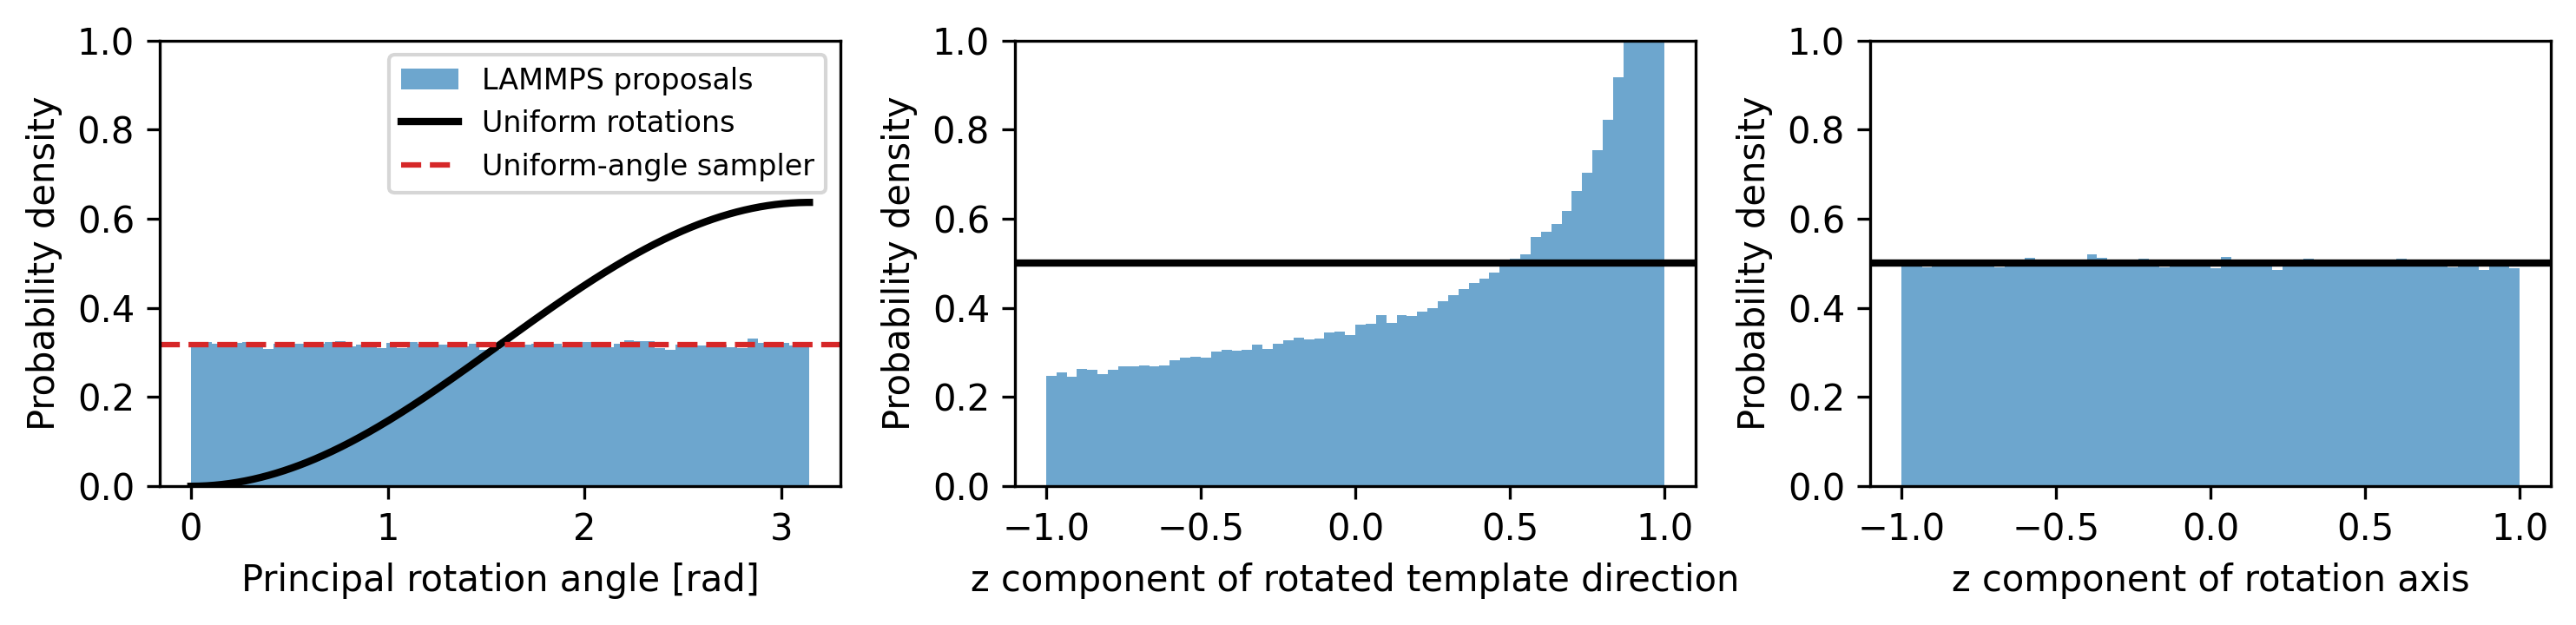

In [79]:

fig, axes = plt.subplots(1, 3, figsize=(10, 2.5), dpi=300)

a = np.linspace(0, np.pi, 400)
axes[0].hist(alpha, bins=60, density=True,
             alpha=0.65, label="LAMMPS proposals")
axes[0].plot(a, (1 - np.cos(a)) / np.pi,
             "k-", lw=2, label="Uniform rotations")
axes[0].axhline(1 / np.pi, color="tab:red", ls="--",
                label="Uniform-angle sampler")
axes[0].set(xlabel="Principal rotation angle [rad]",
            ylabel="Probability density")
axes[0].legend(fontsize=8)

axes[1].hist(direction_z, bins=60, range=(-1, 1),
             density=True, alpha=0.65)
axes[1].axhline(0.5, color="k", lw=2)
axes[1].set(xlabel="z component of rotated template direction",
            ylabel="Probability density")

axes[2].hist(axis_z, bins=60, range=(-1, 1),
             density=True, alpha=0.65)
axes[2].axhline(0.5, color="k", lw=2)
axes[2].set(xlabel="z component of rotation axis",
            ylabel="Probability density")

axes[0].set_ylim(0, 1.0)
axes[1].set_ylim(0, 1.0)
axes[2].set_ylim(0, 1.0)
fig.tight_layout()
fig.savefig(output_files[mode], dpi=300)
plt.show()